# ChiliEdgeNet-C14 — (2/3) Evaluation & XAI

**KHONG train.** Nap model da train tu NB1 (`c14_s1.pth` + `c14_s2.pth`) roi chay:
benchmark nhieu (S1 vs S2) · XAI 3 phuong phap · benchmark latency.

**Input can attach:** (1) dataset anh goc, (2) output NB1 chua `c14_s1.pth` & `c14_s2.pth`.
_Phan benchmark nhieu can CA hai checkpoint._

In [25]:
!pip install -q torchinfo

In [26]:
import os, gc, warnings
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from torchinfo import summary as torchinfo_summary
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

torch.manual_seed(42); torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE} | seed=42')

Device: cuda | seed=42


In [27]:
# Config
DATASET_PATH = '/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300'
TRAIN_DIR = os.path.join(DATASET_PATH, 'train')
VAL_DIR   = os.path.join(DATASET_PATH, 'val')
TEST_DIR  = os.path.join(DATASET_PATH, 'test')

IMG_SIZE, BATCH_SIZE = 224, 32
EPOCHS = 30
LR_BACKBONE, LR_NEW = 1e-4, 1e-3
PRETRAINED = True
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Thu muc chua checkpoint da train tu NB1 (c14_s1.pth + c14_s2.pth).
# Chi can sua 1 bien nay khi doi dataset checkpoint tren Kaggle.
CKPT_DIR = '/kaggle/input/datasets/tminhhi/model-ot'

LABEL_SMOOTHING = 0.05
WARMUP_FRAC     = 0.1

# Tiny-LLM Transformer: reduce 96 -> 128, 1 khoi, 196 token
TF_EMBED_DIM, TF_DEPTH = 128, 1
TF_HEADS, TF_KV_HEADS = 4, 2
TF_MLP_RATIO, TF_DROP, TF_ROPE_BASE = 2.0, 0.1, 100.0

# Điểm cắt backbone (features[1:BACKBONE_CUT]):
#   8..14 -> lưới 14x14 = 196 token   (14 -> 96ch, 672K)
#   15    -> lưới 7x7   =  49 token   (160ch, 835K) — features[14] là tầng stride-32
BACKBONE_CUT = 14

# Muc nhieu ap o test-time (khong co mat luc train)
EVAL_SETS_CFG = ['clean', 'blur2', 'dark']   # them 'noise'/'jpeg' neu muon
BLUR_K, DARK_SCALE = 7, 0.4
ISO_SHIFT, ISO_INT = 0.02, 0.1
JPEG_Q = 30

             train  val  test  total
anthracnose    264   81    62    407
healthy        334  102    78    514
leaf_curl      328  104    82    514
leaf_spot      326  101    76    503
yellow_leaf    345  103    75    523
TONG          1597  491   373   2461


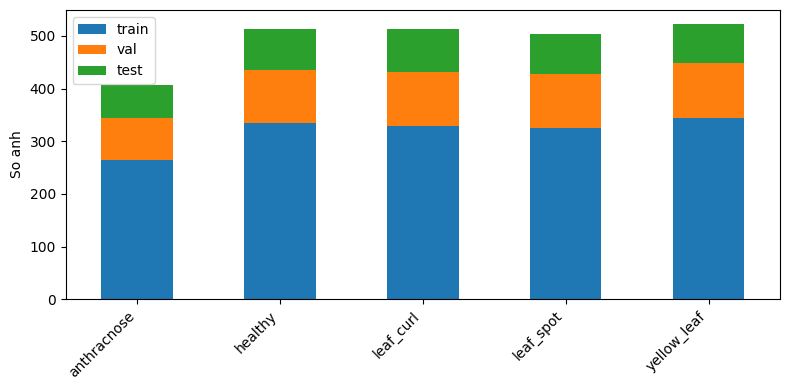

NUM_CLASSES=5 | ['anthracnose', 'healthy', 'leaf_curl', 'leaf_spot', 'yellow_leaf']
Balanced (ratio=1.31) -> no weighting


In [28]:
# Dataset: class names + distribution + class weights
_ds = ImageFolder(TRAIN_DIR)
class_names = _ds.classes
NUM_CLASSES = len(class_names)
counts = np.bincount([l for _, l in _ds.samples], minlength=NUM_CLASSES)

import pandas as pd
_dist = {}
for _split, _d in [('train', TRAIN_DIR), ('val', VAL_DIR), ('test', TEST_DIR)]:
    _n = np.bincount([l for _, l in ImageFolder(_d).samples], minlength=NUM_CLASSES)
    _dist[_split] = _n
dist_df = pd.DataFrame(_dist, index=class_names)
dist_df['total'] = dist_df.sum(axis=1)
dist_df.loc['TONG'] = dist_df.sum()
print(dist_df.to_string())
dist_df.to_csv('c14_class_distribution.csv')

fig, ax = plt.subplots(figsize=(max(8, NUM_CLASSES * 0.9), 4))
dist_df.drop(index='TONG')[['train', 'val', 'test']].plot(kind='bar', stacked=True, ax=ax)
ax.set_ylabel('So anh'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.savefig('c14_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f'NUM_CLASSES={NUM_CLASSES} | {class_names}')
ratio = counts.max() / counts.min()
if ratio >= 1.5:
    cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES),
                              y=np.array([l for _, l in _ds.samples]))
    CLASS_WEIGHTS = torch.tensor(cw, dtype=torch.float32)
    print(f'Imbalanced (ratio={ratio:.2f}) -> class weights ON')
else:
    CLASS_WEIGHTS = None
    print(f'Balanced (ratio={ratio:.2f}) -> no weighting')
del _ds

In [29]:
# ===== TINY-LLM TRANSFORMER (RMSNorm + RoPE-2D + GQA) — dong gop chinh cua model =====
class RMSNorm(nn.Module):
    """Chuan hoa theo RMS (khong tru mean nhu LayerNorm) — nhe hon, dung trong LLM (LLaMA)."""
    def __init__(self, dim, eps=1e-6):
        super().__init__(); self.eps, self.weight = eps, nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def build_axial_rope(gh, gw, head_dim, base=100.0):
    """RoPE-2D: sinh cos/sin ma hoa vi tri (hang, cot) cua luoi token bang phep xoay.
    Nua dau head_dim cho toa do y (hang), nua sau cho x (cot). 0 tham so hoc.
    Tra (cos_y, sin_y, cos_x, sin_x)."""
    d = head_dim // 2
    assert d % 2 == 0, 'head_dim phai chia het 4'
    inv = 1.0 / (base ** (torch.arange(0, d, 2).float() / d))
    gy = torch.arange(gh).float().view(gh, 1).expand(gh, gw).reshape(-1)
    gx = torch.arange(gw).float().view(1, gw).expand(gh, gw).reshape(-1)
    ey = torch.cat([torch.outer(gy, inv)] * 2, dim=-1)
    ex = torch.cat([torch.outer(gx, inv)] * 2, dim=-1)
    return ey.cos()[None,None], ey.sin()[None,None], ex.cos()[None,None], ex.sin()[None,None]

def _rot_half(x):
    """Phep xoay cua RoPE trong khong gian embedding: [x1, x2] -> [-x2, x1]."""
    x1, x2 = x[..., :x.shape[-1]//2], x[..., x.shape[-1]//2:]
    return torch.cat((-x2, x1), dim=-1)

def apply_rope2d(t, cy, sy, cx, sx):
    """Ap RoPE-2D: nua dau embedding xoay theo y, nua sau xoay theo x."""
    d = t.shape[-1] // 2
    ty, tx = t[..., :d], t[..., d:]
    ty = ty * cy + _rot_half(ty) * sy
    tx = tx * cx + _rot_half(tx) * sx
    return torch.cat([ty, tx], dim=-1)

class GroupedQueryAttention(nn.Module):
    """Attention kieu LLM: nh query head dung chung nkv KV head (nh > nkv)
    -> giam tham so & bo nho so voi Multi-Head Attention chuan. O day nh=4, nkv=2."""
    def __init__(self, dim, nh, nkv, dropout=0.0):
        super().__init__()
        assert dim % nh == 0 and nh % nkv == 0
        self.nh, self.nkv, self.hd = nh, nkv, dim // nh
        self.groups, self.scale = nh // nkv, (dim // nh) ** -0.5
        self.q = nn.Linear(dim, nh * self.hd, bias=False)
        self.k = nn.Linear(dim, nkv * self.hd, bias=False)
        self.v = nn.Linear(dim, nkv * self.hd, bias=False)
        self.o = nn.Linear(nh * self.hd, dim, bias=False)
        self.ad, self.pd = nn.Dropout(dropout), nn.Dropout(dropout)
    def forward(self, x, rope):
        B, N, _ = x.shape; cy, sy, cx, sx = rope
        q = self.q(x).view(B, N, self.nh, self.hd).transpose(1, 2)
        k = self.k(x).view(B, N, self.nkv, self.hd).transpose(1, 2)
        v = self.v(x).view(B, N, self.nkv, self.hd).transpose(1, 2)
        q, k = apply_rope2d(q, cy, sy, cx, sx), apply_rope2d(k, cy, sy, cx, sx)  # gan vi tri vao q,k
        if self.groups > 1:                              # lap KV cho du so query head
            k = k.repeat_interleave(self.groups, dim=1)
            v = v.repeat_interleave(self.groups, dim=1)
        attn = self.ad(((q @ k.transpose(-2, -1)) * self.scale).softmax(-1))
        return self.pd(self.o((attn @ v).transpose(1, 2).reshape(B, N, -1)))

class TinyLLMBlock(nn.Module):
    """1 khoi transformer kieu LLM: pre-RMSNorm + GQA(RoPE) residual, roi pre-RMSNorm + MLP(GELU) residual."""
    def __init__(self, dim, nh, nkv, mlp_ratio=2.0, dropout=0.1):
        super().__init__()
        self.n1 = RMSNorm(dim); self.attn = GroupedQueryAttention(dim, nh, nkv, dropout)
        self.n2 = RMSNorm(dim); h = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(dim, h), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(h, dim), nn.Dropout(dropout))
    def forward(self, x, rope):
        x = x + self.attn(self.n1(x), rope)
        return x + self.mlp(self.n2(x))

# ===== MODEL DE XUAT: ChiliEdgeNet (khop 100% class dung de train o NB1) =====
class ChiliEdgeNet(nn.Module):
    """MobileNetV2 cat som (features[0:cut]) trich dac trung -> Conv1x1 giam chieu ve embed_dim
    -> chuoi 196 token (14x14) -> depth khoi Tiny-LLM Transformer -> pool trung binh -> phan lop."""
    def __init__(self, num_classes, pretrained=True, cut=BACKBONE_CUT,
                 embed_dim=TF_EMBED_DIM, depth=TF_DEPTH, heads=TF_HEADS, kv_heads=TF_KV_HEADS,
                 mlp_ratio=TF_MLP_RATIO, drop=TF_DROP, rope_base=TF_ROPE_BASE):
        super().__init__()
        w = torchvision.models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
        base = torchvision.models.mobilenet_v2(weights=w)
        self.first_conv = base.features[0]
        self.backbone = nn.Sequential(*list(base.features[1:cut]))
        # suy ra so kenh + kich thuoc luoi ra cua backbone (chay thu 1 tensor rong)
        with torch.no_grad():
            feat = self.backbone(self.first_conv(torch.zeros(1,3,IMG_SIZE,IMG_SIZE)))
        c_out, grid = feat.shape[1], feat.shape[2]
        self.reduce = nn.Sequential(nn.Conv2d(c_out, embed_dim, 1, bias=False),   # giam kenh -> embed_dim
                                    nn.BatchNorm2d(embed_dim), nn.GELU())
        self.emb_drop = nn.Dropout(drop)
        cy, sy, cx, sx = build_axial_rope(grid, grid, embed_dim // heads, base=rope_base)
        for n, b in zip(['rcy','rsy','rcx','rsx'], [cy, sy, cx, sx]):
            self.register_buffer(n, b, persistent=False)     # RoPE la buffer, khong phai tham so hoc
        self.encoder = nn.ModuleList([TinyLLMBlock(embed_dim, heads, kv_heads, mlp_ratio, drop)
                                      for _ in range(depth)])
        self.norm = RMSNorm(embed_dim)
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(embed_dim, num_classes)
        print(f'[ChiliEdgeNet] backbone out: {c_out}ch @ {grid}x{grid} -> {grid*grid} token')
    def forward(self, x):
        x = self.backbone(self.first_conv(x))                            # CNN trich dac trung
        x = self.emb_drop(self.reduce(x).flatten(2).transpose(1, 2))     # (B,C,H,W) -> (B, HxW token, embed)
        rope = (self.rcy, self.rsy, self.rcx, self.rsx)
        for blk in self.encoder:
            x = blk(x, rope)
        return self.fc(self.drop(self.norm(x).mean(dim=1)))              # pool token -> phan lop

print('ChiliEdgeNet loaded.')

def build_main():
    """Tao model de xuat cuoi cung (ChiliEdgeNet): cut=14, CNN backbone + Tiny-LLM Transformer.
    KHONG con TripletAttention/RES_Block (da bi loai khoi kien truc de xuat tu NB1)."""
    return ChiliEdgeNet(NUM_CLASSES, pretrained=PRETRAINED).to(DEVICE)

ChiliEdgeNet loaded.


In [30]:
# ===== Helpers: seed, loss/optimizer/scheduler, vong train & eval, bao cao =====
import math, random

SEED = 42

def set_seed(seed=SEED):
    """Co dinh moi nguon ngau nhien (Python / NumPy / PyTorch CPU + CUDA) de tai lap."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def make_criterion():
    """CrossEntropy + label smoothing; tu gan class_weights neu dataset lech lop."""
    weight = CLASS_WEIGHTS.to(DEVICE) if CLASS_WEIGHTS is not None else None
    return nn.CrossEntropyLoss(weight=weight, label_smoothing=LABEL_SMOOTHING)

def make_optimizer(model):
    """Adam 2 nhom learning-rate: backbone (pretrained) hoc cham, phan moi hoc nhanh."""
    backbone_prefix = ('first_conv', 'backbone')
    backbone_params = [p for name, p in model.named_parameters()
                       if p.requires_grad and name.startswith(backbone_prefix)]
    new_params      = [p for name, p in model.named_parameters()
                       if p.requires_grad and not name.startswith(backbone_prefix)]
    return torch.optim.Adam(
        [{'params': backbone_params, 'lr': LR_BACKBONE},
         {'params': new_params,      'lr': LR_NEW}], lr=LR_NEW)

def make_scheduler(optimizer, epochs):
    """Linear warmup (WARMUP_FRAC epoch dau) roi cosine decay ve 0."""
    warmup = max(1, int(WARMUP_FRAC * epochs))
    def lr_scale(epoch):                              # epoch: 0-indexed
        if epoch < warmup:
            return (epoch + 1) / warmup               # tang tuyen tinh
        progress = (epoch - warmup) / max(1, epochs - warmup)
        return 0.5 * (1 + math.cos(math.pi * progress))   # cosine giam dan
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_scale)

def train_one_epoch(model, loader, optimizer, criterion):
    """Chay 1 epoch train; tra ve (loss trung binh, accuracy) tren tap train."""
    model.train()
    total_loss = correct = seen = 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        seen       += images.size(0)
    return total_loss / seen, correct / seen

@torch.no_grad()
def evaluate(model, loader, criterion):
    """Danh gia khong cap nhat gradient; tra ve (loss, accuracy, du_doan, nhan_that)."""
    model.eval()
    total_loss = correct = seen = 0
    preds, labels_all = [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * images.size(0)
        pred = logits.argmax(1)
        correct += (pred == labels).sum().item()
        seen    += images.size(0)
        preds      += pred.cpu().tolist()
        labels_all += labels.cpu().tolist()
    return total_loss / seen, correct / seen, preds, labels_all

def train_model(model, train_loader, val_loader, criterion, ckpt_path, epochs=None):
    """Train + validate moi epoch, luu checkpoint TOT NHAT theo val_acc, reload truoc khi tra ve."""
    epochs = epochs or EPOCHS
    optimizer = make_optimizer(model)
    scheduler = make_scheduler(optimizer, epochs)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0.0
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step()
        for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc]):
            history[key].append(value)
        print(f'Epoch {epoch:2d}/{epochs} | train {train_acc:.4f} | val {val_acc:.4f}')
        if val_acc > best_val_acc:                    # chi luu khi val_acc cai thien
            best_val_acc = val_acc
            torch.save(model.state_dict(), ckpt_path)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))   # reload best truoc khi test
    return history

def count_params(model):
    """Tong so tham so cua model."""
    return sum(p.numel() for p in model.parameters())

def report(tag, model, loader):
    """In accuracy / F1-macro / recall-macro / params + classification_report per-class."""
    _, acc, preds, labels_all = evaluate(model, loader, make_criterion())
    f1     = f1_score(labels_all, preds, average='macro')
    recall = recall_score(labels_all, preds, average='macro')
    print(f'[{tag}] acc={acc:.4f} f1={f1:.4f} recall={recall:.4f} params={count_params(model):,}')
    print(classification_report(labels_all, preds, target_names=class_names, digits=4))
    return acc, f1, preds, labels_all

def plot_cm(labels_all, preds, title, path, cmap='Blues'):
    """Ve + luu confusion matrix (dpi=300)."""
    cm = confusion_matrix(labels_all, preds)
    fig, ax = plt.subplots(figsize=(max(6, NUM_CLASSES), max(5, NUM_CLASSES - 1)))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    plt.tight_layout(); plt.savefig(path, dpi=300, bbox_inches='tight'); plt.show()

def plot_curve(history, title, path):
    """Ve + luu learning curve (loss & accuracy theo epoch)."""
    epochs_range = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(epochs_range, history['train_loss'], label='train')
    ax[0].plot(epochs_range, history['val_loss'], label='val')
    ax[0].set_title('Loss'); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(epochs_range, history['train_acc'], label='train')
    ax[1].plot(epochs_range, history['val_acc'], label='val')
    ax[1].set_title('Accuracy'); ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(path, dpi=300, bbox_inches='tight'); plt.show()

print('Helpers loaded (label smoothing + cosine warmup).')

Helpers loaded (label smoothing + cosine warmup).


In [31]:
# ===== Loaders (KHONG train) =====
tf_plain = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])
train_loader1 = DataLoader(ImageFolder(TRAIN_DIR, tf_plain), BATCH_SIZE, shuffle=True,  num_workers=4, pin_memory=True)
val_loader1   = DataLoader(ImageFolder(VAL_DIR,   tf_plain), BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader1  = DataLoader(ImageFolder(TEST_DIR,  tf_plain), BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

tf_aug = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomRotation(30),
                    T.ColorJitter(0.3, 0.3, 0.2, 0.1), T.RandomHorizontalFlip(),
                    T.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.85, 1.15), shear=10),
                    T.ToTensor(), T.Normalize(MEAN, STD)])
train_loader2 = DataLoader(ImageFolder(TRAIN_DIR, tf_aug), BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader2, test_loader2 = val_loader1, test_loader1
print('Loaders san sang (khong train).')

Loaders san sang (khong train).


In [32]:
# ===== Nap model da train tu NB1 (C14_1_Train) qua checkpoint =====
import glob

def _find_ckpt(fname):
    cands = ([os.path.join(CKPT_DIR, fname), fname, './' + fname]
             + sorted(glob.glob('/kaggle/input/**/' + fname, recursive=True)))
    return next((p for p in cands if os.path.exists(p)), None)

CKPT_S2 = _find_ckpt('c14_s2_seed42.pth')
CKPT_S1 = _find_ckpt('c14_s1_seed42.pth')
print('S2 ckpt:', CKPT_S2)
print('S1 ckpt:', CKPT_S1)
assert CKPT_S2, 'Khong thay c14_s2.pth -> hay Add Input output cua NB1 (C14_1_Train)'
assert CKPT_S1, 'Notebook nay can CA c14_s1.pth (benchmark so baseline vs augmented) -> Add Input NB1'

set_seed()
model_s2 = build_main()
model_s2.load_state_dict(torch.load(CKPT_S2, map_location=DEVICE))
model_s2.eval()
xai_model = model_s2

model_s1 = None
if CKPT_S1:
    set_seed()
    model_s1 = build_main()
    model_s1.load_state_dict(torch.load(CKPT_S1, map_location=DEVICE))
    model_s1.eval()
print('Da nap model_s2 (de xuat)' + (' + model_s1 (baseline)' if model_s1 is not None else ' | khong co S1'))

S2 ckpt: /kaggle/input/datasets/tminhhi/model-ot/c14_s2_seed123.pth
S1 ckpt: /kaggle/input/datasets/tminhhi/model-ot/c14_s2_seed123.pth
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 123MB/s]


[ChiliEdgeNet] backbone out: 96ch @ 14x14 -> 196 token
[ChiliEdgeNet] backbone out: 96ch @ 14x14 -> 196 token
Da nap model_s2 (de xuat) + model_s1 (baseline)


---
## Benchmark nhiễu — clean + 4 điều kiện

Bốn phép nhiễu áp ở test-time theo tinh thần ImageNet-C: Gaussian blur (k=5),
giảm sáng (×0.4), ISO noise (0.1), nén JPEG (q=30). Không phép nào có mặt lúc train.
Nhiễu sinh một lần và cố định seed, nên mọi model chấm trên đúng cùng từng pixel.


In [33]:
# ===== Bo test nhieu: clean + blur/dark/noise/jpeg =====
import io, random
import numpy as np
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset

try:
    import albumentations as A
except ImportError:
    import subprocess; subprocess.run(['pip', 'install', '-q', 'albumentations'], check=True)
    import albumentations as A

_test_raw = ImageFolder(TEST_DIR)
assert _test_raw.classes == class_names
N_TEST = len(_test_raw.samples)
clean_arr = np.zeros((N_TEST, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
labels_arr = np.zeros(N_TEST, dtype=np.int64)
for i, (p, l) in enumerate(_test_raw.samples):
    clean_arr[i] = np.array(Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    labels_arr[i] = l

_blur_t = A.GaussianBlur(blur_limit=(BLUR_K, BLUR_K), p=1.0)
_iso_t = A.ISONoise(color_shift=(ISO_SHIFT, ISO_SHIFT), intensity=(ISO_INT, ISO_INT), p=1.0)

def _jpeg_one(img, q=JPEG_Q):
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format='JPEG', quality=q)
    return np.array(Image.open(buf).convert('RGB'))

ARRS = {'clean': clean_arr}
if 'blur2' in EVAL_SETS_CFG:
    ARRS['blur2'] = np.empty_like(clean_arr)
if 'dark' in EVAL_SETS_CFG:
    ARRS['dark'] = np.clip(clean_arr.astype(np.float32) * DARK_SCALE, 0, 255).astype(np.uint8)
if 'noise' in EVAL_SETS_CFG:
    ARRS['noise'] = np.empty_like(clean_arr)
if 'jpeg' in EVAL_SETS_CFG:
    ARRS['jpeg'] = np.empty_like(clean_arr)

for i in range(N_TEST):
    # Seed truoc moi phep bien doi: GaussianBlur/ISONoise deu boc tham so ngau nhien.
    if 'blur2' in ARRS:
        random.seed(20_000 + i); np.random.seed(20_000 + i)
        if hasattr(_blur_t, 'set_random_seed'):
            try: _blur_t.set_random_seed(20_000 + i)
            except Exception: pass
        ARRS['blur2'][i] = _blur_t(image=clean_arr[i])['image']
    if 'noise' in ARRS:
        random.seed(10_000 + i); np.random.seed(10_000 + i)
        if hasattr(_iso_t, 'set_random_seed'):
            try: _iso_t.set_random_seed(10_000 + i)
            except Exception: pass
        ARRS['noise'][i] = _iso_t(image=clean_arr[i])['image']
    if 'jpeg' in ARRS:
        ARRS['jpeg'][i] = _jpeg_one(clean_arr[i])
EVAL_SETS = list(ARRS)

_MEAN_T = torch.tensor(MEAN).view(3, 1, 1)
_STD_T  = torch.tensor(STD).view(3, 1, 1)

class _ArrDS(Dataset):
    def __init__(self, arr): self.arr = arr
    def __len__(self): return len(self.arr)
    def __getitem__(self, i):
        x = torch.from_numpy(self.arr[i]).permute(2, 0, 1).float().div_(255)
        return (x - _MEAN_T) / _STD_T, int(labels_arr[i])

@torch.no_grad()
def predict_arr(m, arr):
    m.eval(); out = []
    for x, _ in DataLoader(_ArrDS(arr), BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True):
        out += m(x.to(DEVICE)).argmax(1).cpu().tolist()
    return np.array(out)

print(f'{N_TEST} anh x {len(EVAL_SETS)} bo: {EVAL_SETS}')

373 anh x 3 bo: ['clean', 'blur2', 'dark']


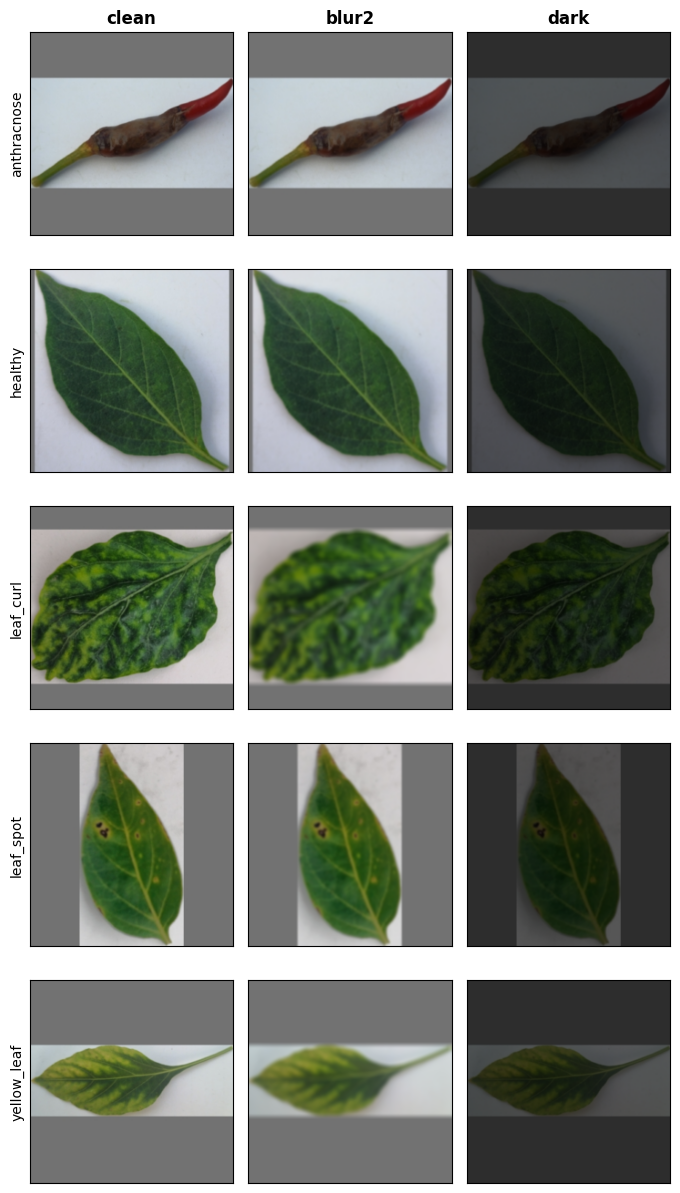

anthracnose  <- IMG_20260427_164757.jpg
healthy      <- IMG_20260427_165538.jpg
leaf_curl    <- IMG_20260213_161906.jpg
leaf_spot    <- IMG_20260425_165846.jpg
yellow_leaf  <- IMG_20260207_163538.jpg

Muc nhieu do tren toan bo 373 anh (so voi clean):
nhieu  sai_khac_TB  sai_khac_max  pct_pixel_doi  PSNR_dB
blur2         1.92          98.0          21.41    33.45
 dark        76.22         148.0          99.97     9.86

PSNR cao = mat kho thay. Nhieu van danh sap accuracy -> do la luan diem cua bai.


In [34]:
# ===== Xem bo anh nhieu: 5 lop x (clean + 4 dieu kien) =====
# Dien path anh muon xem; de '' -> tu lay anh dau tien cua lop.
BENCH_SAMPLE = {
    'anthracnose':  r'/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300/test/anthracnose/IMG_20260427_164757.jpg',
    'healthy':      r'/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300/test/healthy/IMG_20260427_165538.jpg',
    'leaf_curl':    r'/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300/test/leaf_curl/IMG_20260213_161906.jpg',
    'leaf_spot':    r'/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300/test/leaf_spot/IMG_20260425_165846.jpg',
    'yellow_leaf':  r'/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300/test/yellow_leaf/IMG_20260207_163538.jpg',
}

_sel_rows = []
for _ci, _cname in enumerate(class_names):
    _sel = BENCH_SAMPLE.get(_cname, '').strip()
    _idx = None
    if _sel:
        _want = os.path.normpath(_sel)
        for _k, (_p, _l) in enumerate(_test_raw.samples):
            if os.path.normpath(_p) == _want or os.path.basename(_p) == os.path.basename(_sel):
                _idx = _k; break
        if _idx is None:
            print(f'[!] Khong thay anh chi dinh cho "{_cname}": {_sel} -> dung anh dau tien')
    if _idx is None:
        _idx = next(_k for _k, (_p, _l) in enumerate(_test_raw.samples) if _l == _ci)
    _sel_rows.append((_cname, _idx, os.path.basename(_test_raw.samples[_idx][0])))

fig, axes = plt.subplots(len(_sel_rows), len(EVAL_SETS),
                         figsize=(2.3 * len(EVAL_SETS), 2.45 * len(_sel_rows)), squeeze=False)
for _r, (_cname, _idx, _fn) in enumerate(_sel_rows):
    for _c, _s in enumerate(EVAL_SETS):
        _ax = axes[_r][_c]
        _ax.imshow(ARRS[_s][_idx]); _ax.set_xticks([]); _ax.set_yticks([])
        if _r == 0:
            _ax.set_title(_s, fontsize=12, fontweight='bold')
        if _c == 0:
            _ax.set_ylabel(_cname, fontsize=10)
plt.tight_layout()
plt.savefig('c14_bench_samples.png', dpi=200, bbox_inches='tight')
plt.show()

for _cname, _idx, _fn in _sel_rows:
    print(f'{_cname:12s} <- {_fn}')

# Do severity bang SO, khong cai bang mat: PSNR + sai khac pixel tren toan bo 373 anh.
# PSNR cang cao = anh cang giong clean. Nhieu ISO/JPEG co PSNR cao (mat kho thay)
# nhung van danh sap accuracy -> do chinh la luan diem.
_sev = []
_cl = clean_arr.astype(np.float32)
for _s in EVAL_SETS:
    if _s == 'clean':
        continue
    _d = ARRS[_s].astype(np.float32) - _cl
    _mse = float((_d ** 2).mean())
    _psnr = 10 * math.log10(255.0 ** 2 / _mse) if _mse > 0 else float('inf')
    _sev.append({'nhieu': _s,
                 'sai_khac_TB': float(np.abs(_d).mean()),
                 'sai_khac_max': float(np.abs(_d).max()),
                 'pct_pixel_doi': float((np.abs(_d) > 1).mean() * 100),
                 'PSNR_dB': _psnr})
sev_df = pd.DataFrame(_sev)
sev_df.to_csv('c14_severity.csv', index=False)
print()
print(f'Muc nhieu do tren toan bo {N_TEST} anh (so voi clean):')
print(sev_df.round(2).to_string(index=False))
print()
print('PSNR cao = mat kho thay. Nhieu van danh sap accuracy -> do la luan diem cua bai.')

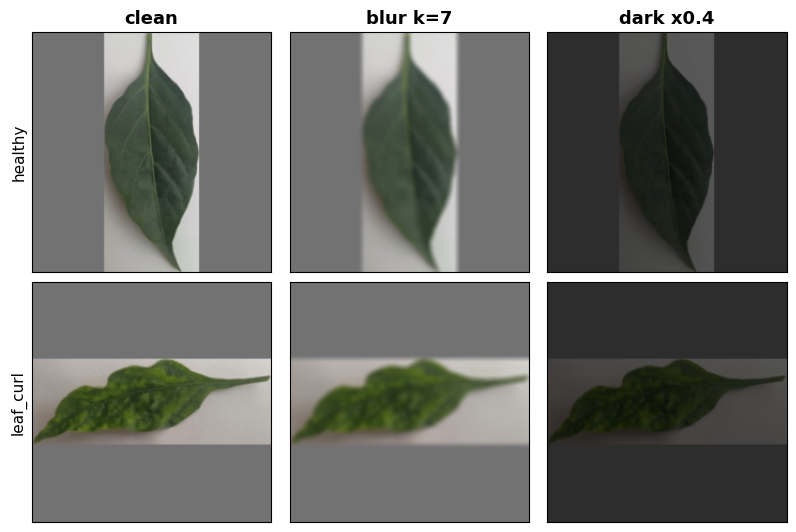

-> c14_bench_paper.png
  healthy      <- IMG_20260207_165457.jpg
  leaf_curl    <- IMG_20260207_164942.jpg

[i] Hinh nay KHONG co cot noise. Truc noise la ket qua chinh cua bai
    (Transformer +4.02pp, p=0.008) — nho dam bao no van xuat hien o hinh khac.


In [35]:
# ===== Hinh bo nhieu cho BAI BAO: tu chon lop + tu chon dieu kien =====
# Khac cell luoi 5x5 o tren (ve tat ca de soi), cell nay chi ve dung thu dua vao bai.
# Van lay tu ARRS -> dung tung pixel model da cham diem.

FIG_SETS = list(EVAL_SETS_CFG)                      # mac dinh bam theo Config
FIG_IMGS = {                                        # '' -> tu lay anh dau tien cua lop
    'healthy':   '',
    'leaf_curl': '',
}
FIG_ZOOM = 0            # 0 = chi toan anh | >0 = them hang cat can (vd 72)
FIG_OUT  = 'c14_bench_paper.png'

_LABEL = {'clean': 'clean', 'blur2': f'blur k={BLUR_K}', 'dark': f'dark x{DARK_SCALE}',
          'noise': f'ISO {ISO_INT}', 'jpeg': f'JPEG q={JPEG_Q}'}
for _s in FIG_SETS:
    assert _s in ARRS, f'khong biet dieu kien: {_s}'

_rows = []
for _cname, _want in FIG_IMGS.items():
    assert _cname in class_names, f'khong co lop: {_cname}'
    _ci = class_names.index(_cname)
    _idx = None
    if _want.strip():
        _base = os.path.basename(_want.strip())
        for _k, (_p, _l) in enumerate(_test_raw.samples):
            if os.path.normpath(_p) == os.path.normpath(_want.strip()) or os.path.basename(_p) == _base:
                _idx = _k; break
        if _idx is None:
            print(f'[!] Khong thay anh chi dinh cho "{_cname}" -> dung anh dau tien')
    if _idx is None:
        _idx = next(_k for _k, (_p, _l) in enumerate(_test_raw.samples) if _l == _ci)
    _rows.append((_cname, _idx))

_nr = len(_rows) * (2 if FIG_ZOOM else 1)
fig, axes = plt.subplots(_nr, len(FIG_SETS),
                         figsize=(2.7 * len(FIG_SETS), 2.7 * _nr), squeeze=False)
_r = 0
for _cname, _idx in _rows:
    for _c, _s in enumerate(FIG_SETS):
        axes[_r][_c].imshow(ARRS[_s][_idx])
        axes[_r][_c].set_xticks([]); axes[_r][_c].set_yticks([])
        if _r == 0:
            axes[_r][_c].set_title(_LABEL[_s], fontsize=13, fontweight='bold')
    axes[_r][0].set_ylabel(_cname, fontsize=11)
    _r += 1
    if FIG_ZOOM:
        _zc, _zh = IMG_SIZE // 2, FIG_ZOOM // 2
        for _c, _s in enumerate(FIG_SETS):
            axes[_r][_c].imshow(ARRS[_s][_idx][_zc - _zh:_zc + _zh, _zc - _zh:_zc + _zh],
                                interpolation='nearest')
            axes[_r][_c].set_xticks([]); axes[_r][_c].set_yticks([])
        axes[_r][0].set_ylabel(f'{_cname}\n(cat {FIG_ZOOM}px)', fontsize=10)
        _r += 1

plt.tight_layout()
plt.savefig(FIG_OUT, dpi=300, bbox_inches='tight')
plt.show()

print(f'-> {FIG_OUT}')
for _cname, _idx in _rows:
    print(f'  {_cname:12s} <- {os.path.basename(_test_raw.samples[_idx][0])}')
if 'noise' not in FIG_SETS:
    print()
    print('[i] Hinh nay KHONG co cot noise. Truc noise la ket qua chinh cua bai')
    print('    (Transformer +4.02pp, p=0.008) — nho dam bao no van xuat hien o hinh khac.')

In [36]:
# ===== Cham diem + luu ket qua =====
from sklearn.metrics import f1_score

_rows, _frames = [], []
for _name, _m in [('S1 baseline', model_s1), ('S2 augmented', model_s2)]:
    for _s in EVAL_SETS:
        _p = predict_arr(_m, ARRS[_s])
        _rows.append({'model': _name, 'set': _s, 'params': count_params(_m),
                      'acc': float((_p == labels_arr).mean()),
                      'f1_macro': f1_score(labels_arr, _p, average='macro')})
        _frames.append(pd.DataFrame({'model': _name, 'set': _s, 'idx': np.arange(N_TEST),
                                     'true': labels_arr, 'pred': _p}))
bench = pd.DataFrame(_rows)
RESULT_CSV_BENCH = 'c14_bench_results.csv'
bench.to_csv(RESULT_CSV_BENCH, index=False)
pd.concat(_frames, ignore_index=True).to_csv('c14_bench_preds.csv', index=False)

def wilson_ci(k, n, z=1.96):
    """Wilson score 95% CI cho ty le — hop ly hon Wald khi n nho / p gan 1 (gop y #6)."""
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

bench['n_dung'] = (bench['acc'] * N_TEST).round().astype(int)
_ci = bench.apply(lambda r: wilson_ci(r['n_dung'], N_TEST), axis=1)
bench['ci95_lo'] = [x[0] for x in _ci]
bench['ci95_hi'] = [x[1] for x in _ci]
bench.to_csv(RESULT_CSV_BENCH, index=False)

_piv = bench.pivot(index='model', columns='set', values='acc')[EVAL_SETS] * 100
_piv['mean5'] = _piv.mean(axis=1)
print(_piv.round(2).to_string())
print()
print(f'Wilson 95% CI (n={N_TEST}):')
for _, _r in bench.iterrows():
    print(f"  {_r['model']:13s} {_r['set']:6s} {_r['acc']*100:6.2f}%  "
          f"[{_r['ci95_lo']*100:6.2f} , {_r['ci95_hi']*100:6.2f}]  ({_r['n_dung']}/{N_TEST})")

set           clean  blur2  dark  mean5
model                                  
S1 baseline    99.2  95.98  99.2  98.12
S2 augmented   99.2  95.98  99.2  98.12

Wilson 95% CI (n=373):
  S1 baseline   clean   99.20%  [ 97.66 ,  99.73]  (370/373)
  S1 baseline   blur2   95.98%  [ 93.47 ,  97.55]  (358/373)
  S1 baseline   dark    99.20%  [ 97.66 ,  99.73]  (370/373)
  S2 augmented  clean   99.20%  [ 97.66 ,  99.73]  (370/373)
  S2 augmented  blur2   95.98%  [ 93.47 ,  97.55]  (358/373)
  S2 augmented  dark    99.20%  [ 97.66 ,  99.73]  (370/373)


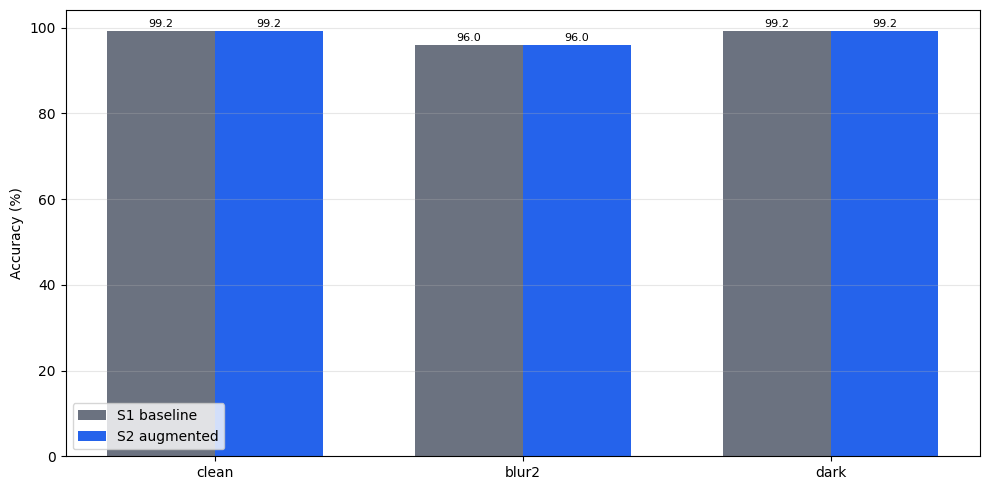

8426

In [37]:
# ===== Bieu do benchmark nhieu =====
fig, ax = plt.subplots(figsize=(10, 5))
_x = np.arange(len(EVAL_SETS)); _w = 0.35
for _j, (_name, _c) in enumerate(zip(['S1 baseline', 'S2 augmented'], ['#6b7280', '#2563eb'])):
    _ys = [bench[(bench.model == _name) & (bench.set == _s)].acc.iloc[0] * 100 for _s in EVAL_SETS]
    _bars = ax.bar(_x + (_j - 0.5) * _w, _ys, width=_w, color=_c, label=_name)
    for _b, _y in zip(_bars, _ys):
        ax.annotate(f'{_y:.1f}', (_b.get_x() + _b.get_width()/2, _y), ha='center',
                    textcoords='offset points', xytext=(0, 3), fontsize=8)
ax.set_xticks(_x); ax.set_xticklabels(EVAL_SETS)
ax.set_ylabel('Accuracy (%)')
ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.savefig('c14_bench.png', dpi=300, bbox_inches='tight'); plt.show()
torch.cuda.empty_cache(); gc.collect()

In [38]:
!pip install -q captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 9.0 MB/s eta 0:00:00ta 0:00:01


---
## Diễn giải bằng XAI

Ba ky thuat: Attention Rollout (doc noi tai khoi Tiny Transformer), Gradient SHAP
(Captum), Occlusion Sensitivity (Captum). Moi ky thuat chay tren mot anh dai dien
moi lop, xuat heatmap ra `xai_*.png`. Dung `model_s2` (ChiliEdgeNet, augmented).

In [39]:
# ===== XAI setup: model đã train + chọn ảnh cho từng lớp =====
from PIL import Image
import os, numpy as np

xai_model = model_s2          # augmented = model de xuat (muc 4.2); best ckpt da reload
xai_model.eval()

# Anh dai dien moi lop cho XAI: ten file, hoac path day du.
# De '' -> tu lay anh dau tien cua lop.
SAMPLE_OVERRIDE = {
    'anthracnose':  r'/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300/test/anthracnose/IMG_20260427_164757.jpg',
    'healthy':      r'/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300/test/healthy/IMG_20260427_165538.jpg',
    'leaf_curl':    r'/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300/test/leaf_curl/IMG_20260213_161906.jpg',
    'leaf_spot':    r'/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300/test/leaf_spot/IMG_20260425_165846.jpg',
    'yellow_leaf':  r'/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300/test/yellow_leaf/IMG_20260207_163538.jpg',
}

samples = []                  # (path, class_idx, class_name)
for ci, cname in enumerate(class_names):
    cdir = os.path.join(TEST_DIR, cname)
    if not os.path.isdir(cdir):
        continue
    sel = SAMPLE_OVERRIDE.get(cname, '').strip()
    path = None
    if sel:                                   # ảnh do người dùng chỉ định
        cand = sel if (os.path.isabs(sel) or os.path.dirname(sel)) else os.path.join(cdir, sel)
        if os.path.exists(cand):
            path = cand
        else:
            print(f'[!] Không thấy ảnh chỉ định cho "{cname}": {sel} -> dùng ảnh đầu tiên')
    if path is None:                          # fallback: ảnh đầu tiên
        files = sorted(f for f in os.listdir(cdir)
                       if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')))
        if not files:
            continue
        path = os.path.join(cdir, files[0])
    samples.append((path, ci, cname))

def load_img(path):           # -> HWC float32 [0,1], đã resize
    img = Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    return np.array(img).astype('float32') / 255.0

def to_input(arr):            # HWC[0,1] -> tensor chuẩn hoá (1,3,H,W) trên DEVICE
    t = torch.tensor(arr).permute(2, 0, 1)
    return T.Normalize(MEAN, STD)(t).unsqueeze(0).to(DEVICE)

print(f'{len(samples)} ảnh cho XAI:')
for p, _, c in samples:
    print(f'  {c:22s} <- {os.path.basename(p)}')

5 ảnh cho XAI:
  anthracnose            <- IMG_20260427_164757.jpg
  healthy                <- IMG_20260427_165538.jpg
  leaf_curl              <- IMG_20260213_161906.jpg
  leaf_spot              <- IMG_20260425_165846.jpg
  yellow_leaf            <- IMG_20260207_163538.jpg


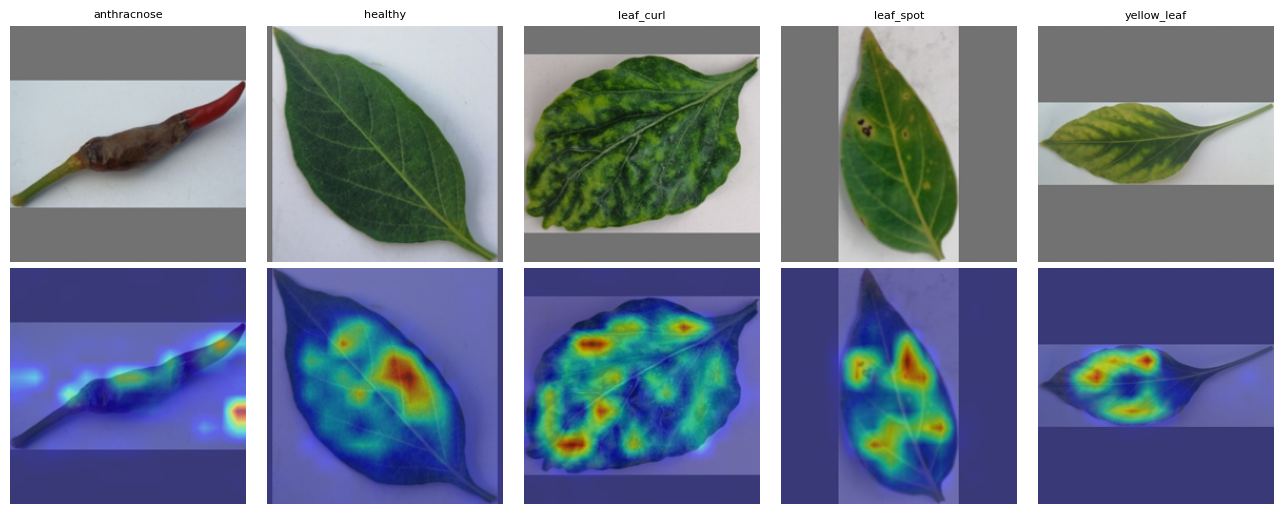

In [40]:
# ===== 1/3 — Attention Rollout (Tiny Transformer) =====
from PIL import Image as PILImage
import math

attn_store = []
def _attn_hook(module, inp):
    x = inp[0]; B, N, _ = x.shape
    q = module.q(x).view(B, N, module.nh,  module.hd).transpose(1, 2)
    k = module.k(x).view(B, N, module.nkv, module.hd).transpose(1, 2)
    rope = (xai_model.rcy, xai_model.rsy, xai_model.rcx, xai_model.rsx)
    q, k = apply_rope2d(q, *rope), apply_rope2d(k, *rope)
    if module.groups > 1:
        k = k.repeat_interleave(module.groups, dim=1)
    a = ((q @ k.transpose(-2, -1)) * module.scale).softmax(-1)   # (B,heads,N,N)
    attn_store.append(a.mean(1).detach())                        # (B,N,N) mean over heads

handles = [blk.attn.register_forward_pre_hook(_attn_hook) for blk in xai_model.encoder]

fig, ax = plt.subplots(2, len(samples), figsize=(2.6 * len(samples), 5.2))
for j, (path, ci, cname) in enumerate(samples):
    arr = load_img(path); attn_store.clear()
    with torch.no_grad():
        _ = xai_model(to_input(arr))
    N = attn_store[0].shape[-1]
    R = torch.eye(N, device=attn_store[0].device)
    for a in attn_store:                       # nhân attention qua các lớp + residual
        a0 = a[0] + torch.eye(N, device=a.device)
        a0 = a0 / a0.sum(-1, keepdim=True)
        R = a0 @ R
    g = int(math.sqrt(N))
    heat = R.mean(0).reshape(g, g).cpu().numpy()
    heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)
    heat = np.array(PILImage.fromarray((heat * 255).astype('uint8')).resize((IMG_SIZE, IMG_SIZE), PILImage.BILINEAR)) / 255.0
    ax[0, j].imshow(arr); ax[0, j].set_title(cname, fontsize=8); ax[0, j].axis('off')
    ax[1, j].imshow(arr); ax[1, j].imshow(heat, cmap='jet', alpha=0.5); ax[1, j].axis('off')
plt.tight_layout()
plt.savefig('xai_attn_rollout.png', dpi=200, bbox_inches='tight'); plt.show()
for h in handles:
    h.remove()

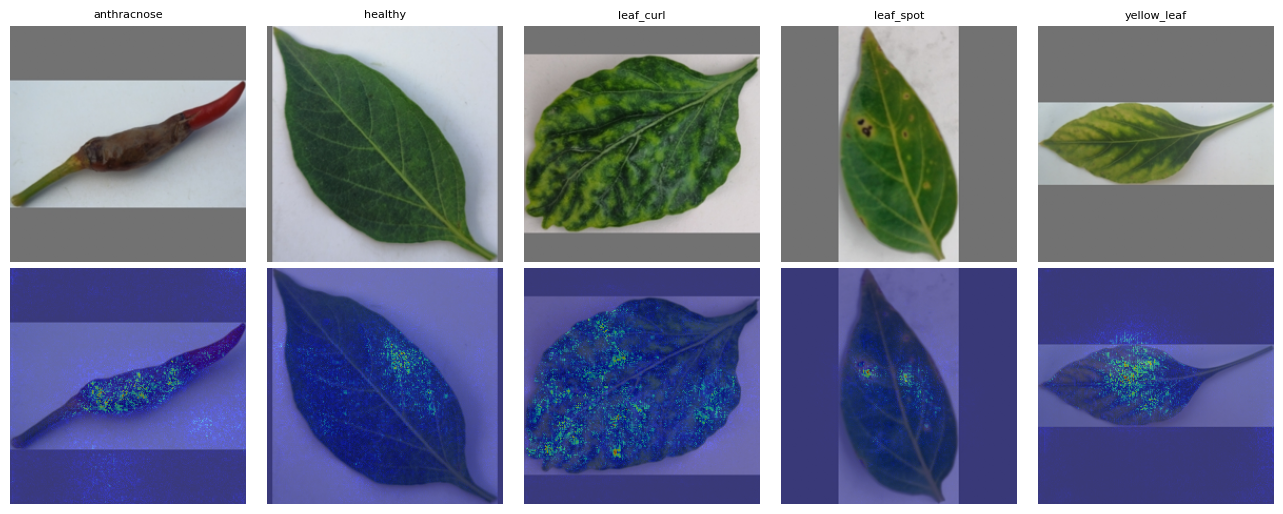

In [41]:
# ===== 2/3 — SHAP (Gradient SHAP, Captum) =====
from captum.attr import GradientShap
gs = GradientShap(xai_model)
fig, ax = plt.subplots(2, len(samples), figsize=(2.6 * len(samples), 5.2))
for j, (path, ci, cname) in enumerate(samples):
    arr = load_img(path); inp = to_input(arr)
    base = torch.cat([inp * 0.0, inp * 0.0 + 1.0])              # phân phối baseline
    attr = gs.attribute(inp, baselines=base, target=int(ci), n_samples=20, stdevs=0.1)
    h = attr.abs().sum(1)[0].detach().cpu().numpy()
    h = (h - h.min()) / (h.max() - h.min() + 1e-8)
    ax[0, j].imshow(arr); ax[0, j].set_title(cname, fontsize=8); ax[0, j].axis('off')
    ax[1, j].imshow(arr); ax[1, j].imshow(h, cmap='jet', alpha=0.5); ax[1, j].axis('off')
plt.tight_layout()
plt.savefig('xai_shap.png', dpi=200, bbox_inches='tight'); plt.show()

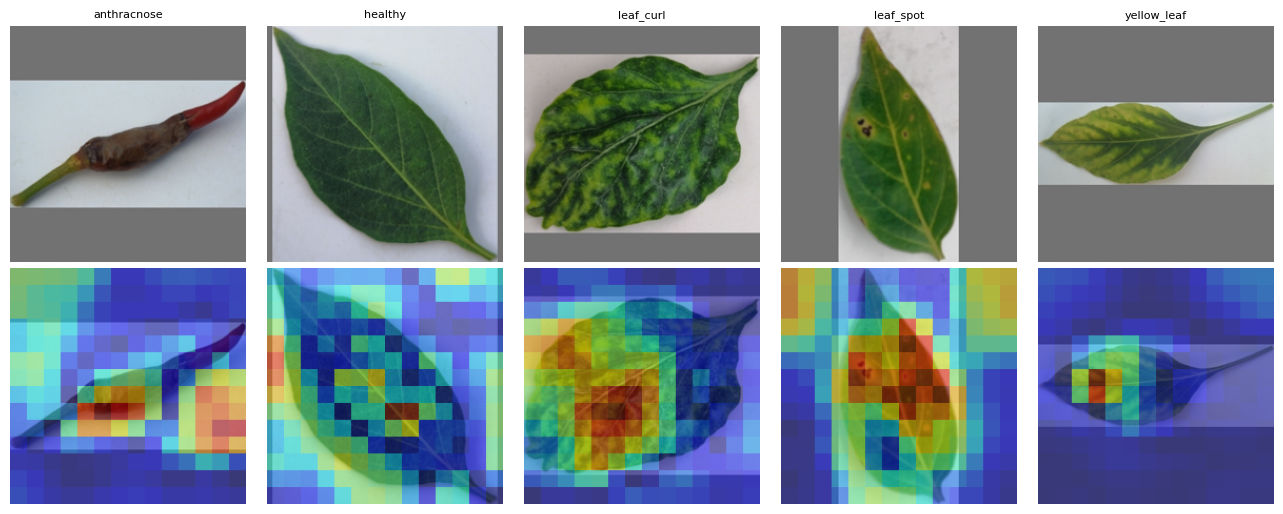

In [42]:
# ===== 3/3 — Occlusion Sensitivity (Captum) =====
from captum.attr import Occlusion
occ = Occlusion(xai_model)
fig, ax = plt.subplots(2, len(samples), figsize=(2.6 * len(samples), 5.2))
for j, (path, ci, cname) in enumerate(samples):
    arr = load_img(path); inp = to_input(arr)
    attr = occ.attribute(inp, target=int(ci), strides=(3, 16, 16),
                         sliding_window_shapes=(3, 32, 32), baselines=0)
    h = attr.abs().sum(1)[0].detach().cpu().numpy()
    h = (h - h.min()) / (h.max() - h.min() + 1e-8)
    ax[0, j].imshow(arr); ax[0, j].set_title(cname, fontsize=8); ax[0, j].axis('off')
    ax[1, j].imshow(arr); ax[1, j].imshow(h, cmap='jet', alpha=0.5); ax[1, j].axis('off')
plt.tight_layout()
plt.savefig('xai_occlusion.png', dpi=200, bbox_inches='tight'); plt.show()

---
## Benchmark Latency

Do tre batch=1 (sat kich ban trien khai tren thiet bi bien) va thong luong
batch=32, do tren CPU va 1 GPU.


In [43]:
# ===== Benchmark Latency: CPU vs 1 GPU (batch=1 va batch=32) =====
import time, platform, subprocess
import pandas as pd

# Cau hinh phan cung — bat buoc de tai lap con so ms/anh (gop y #8)
_cpu_name = platform.processor() or platform.machine()
try:
    _o = subprocess.run(['bash', '-c', "grep -m1 'model name' /proc/cpuinfo | cut -d: -f2"],
                        capture_output=True, text=True, timeout=5).stdout.strip()
    if _o:
        _cpu_name = _o
except Exception:
    pass
print(f'CPU : {_cpu_name} | {os.cpu_count()} loi logic')
print(f'GPU : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "khong co"}')
print(f'torch {torch.__version__} | python {platform.python_version()}')
print()

def benchmark_latency(model, device, n_warmup=10, n_runs=50, batch_size=1):
    model = model.to(device).eval()
    x = torch.randn(batch_size, 3, IMG_SIZE, IMG_SIZE, device=device)
    with torch.no_grad():
        for _ in range(n_warmup):
            _ = model(x)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_runs):
            _ = model(x)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        t1 = time.perf_counter()
    return (t1 - t0) / n_runs / batch_size * 1000

lat_results = []

ms = benchmark_latency(xai_model, torch.device('cpu'), batch_size=1)
lat_results.append({'config': 'CPU (batch=1)', 'ms_per_image': ms, 'images_per_sec': 1000 / ms})
print(f'[CPU batch=1] {ms:.2f} ms/anh  ({1000/ms:.1f} anh/giay)')

if torch.cuda.is_available():
    ms = benchmark_latency(xai_model, torch.device('cuda'), batch_size=1)
    lat_results.append({'config': '1 GPU (batch=1)', 'ms_per_image': ms, 'images_per_sec': 1000 / ms})
    print(f'[1 GPU batch=1] {ms:.2f} ms/anh  ({1000/ms:.1f} anh/giay)')

    ms = benchmark_latency(xai_model, torch.device('cuda'), batch_size=BATCH_SIZE)
    lat_results.append({'config': f'1 GPU (batch={BATCH_SIZE})', 'ms_per_image': ms,
                        'images_per_sec': 1000 / ms})
    print(f'[1 GPU batch={BATCH_SIZE}] {ms:.2f} ms/anh  ({1000/ms:.1f} anh/giay)')
else:
    print('[!] Khong co GPU trong phien nay -> chi do duoc CPU.')

xai_model.to(DEVICE)

lat_df = pd.DataFrame(lat_results)
print()
print(lat_df.to_string(index=False))
lat_df.to_csv('c14_latency_cpu_vs_gpu.csv', index=False)

torch.cuda.empty_cache(); gc.collect()

CPU : Intel(R) Xeon(R) CPU @ 2.00GHz | 4 loi logic
GPU : Tesla T4
torch 2.10.0+cu128 | python 3.12.13

[CPU batch=1] 19.28 ms/anh  (51.9 anh/giay)
[1 GPU batch=1] 5.21 ms/anh  (192.1 anh/giay)
[1 GPU batch=32] 0.82 ms/anh  (1220.1 anh/giay)

          config  ms_per_image  images_per_sec
   CPU (batch=1)     19.281163       51.864091
 1 GPU (batch=1)      5.205857      192.091321
1 GPU (batch=32)      0.819572     1220.149565


35465